In [ ]:
!pip install pandas numpy scikit-learn

In [ ]:
# load da dataset
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv"

df = pd.read_csv(url)
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
# since Unnamed: 0 aint contributing anything to da models, drop (me after 12th) it

df = df.drop(columns=["Unnamed: 0"])
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
# check for missing values and duplicates and remove them
print("Missing Values: \n", df.isnull().sum())
print("\nDuplicates: ", df.duplicated().sum())

df = df.dropna()
df = df.drop_duplicates()

Missing Values: 
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicates:  0


In [ ]:
# check for outliers
for col in df.columns:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  print(f"Outliers in {col}: ", len(outliers), outliers[col].tolist())

Outliers in TV:  0 []
Outliers in Radio:  0 []
Outliers in Newspaper:  2 [114.0, 100.9]
Outliers in Sales:  0 []


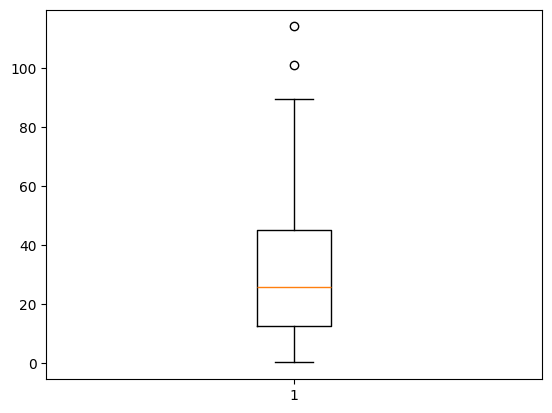

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot(df['Newspaper'])

plt.show()

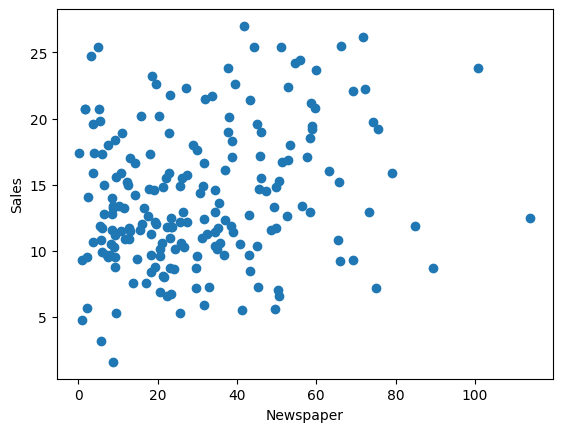

In [ ]:
plt.scatter(df['Newspaper'], df['Sales'])
plt.xlabel('Newspaper')
plt.ylabel('Sales')
plt.show()

In [ ]:
# since the 2 ooutliers are somewhat genuine (not something that is an impossible value), we're gonna keep it (if maam bole remove toh remove the entire row)

In [ ]:
# train and test split  80:20

from sklearn.model_selection import train_test_split

x = df.drop(columns=['Sales'])
y = df['Sales']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Train Set: ",  x_train.shape)
print("Test Set: ",  x_test.shape)

Train Set:  (160, 3)
Test Set:  (40, 3)


In [ ]:
# training 7 diff models for comparision
combos = [['TV'], ['Radio'], ['Newspaper'], ['TV', 'Radio'], ['Radio', 'Newspaper'], ['Newspaper', 'TV'], ['TV', 'Radio', 'Newspaper']]

In [ ]:
# training 7 models and appending each model's RMSE & R2 vals to result array
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
results = []
for combo in combos:
  model = LinearRegression()
  model.fit(x_train[combo], y_train)

  y_pred = model.predict(x_test[combo])
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results.append({'combo': combo, 'rmse': rmse, 'r2': r2})

In [ ]:
# converting res array to a table, rounding off each value to 4 and sorting them accordinf rmse (lower the rmse better the model)
results_df = pd.DataFrame(results).round(4).sort_values('rmse')
results_df

,combo,rmse,r2
3,"[TV, Radio]",1.7714,0.9006
6,"[TV, Radio, Newspaper]",1.7816,0.8994
0,[TV],3.1945,0.6767
5,"[Newspaper, TV]",3.3260,0.6495
4,"[Radio, Newspaper]",4.8171,0.2648
1,[Radio],4.8217,0.2634
2,[Newspaper],5.5336,0.0299


In [ ]:
print("Best Combo: ", results_df.iloc[0].combo)
print("Best RMSE: ", results_df.iloc[0].rmse)
print("Best R2: ", results_df.iloc[0].r2)

Best Combo:  ['TV', 'Radio']
Best RMSE:  1.7714
Best R2:  0.9006
